# MVP — Análise de Dados: A Bilheteria do Cinema no Brasil (2009–2017)

**Pós-graduação em Ciência de Dados e Analytics — PUC-RJ**
Sprint: Análise de Dados | MVP

**Aluno:** Daniel Siqueira
**Dataset:** Bilheteria de Obras por Semana — ANCINE (Dados Abertos do Governo Federal)
**Repositório:** [github.com/danielsiqueiradev/MVP_Analise_De_Dados_PUC-RJ](https://github.com/danielsiqueiradev/MVP_Analise_De_Dados_PUC-RJ)

---

## 1. Definição do Problema

O Brasil é um dos dez maiores mercados de cinema do mundo em número de espectadores, mas convive com um paradoxo conhecido: a esmagadora maioria da renda de bilheteria vem de filmes estrangeiros — sobretudo de Hollywood — enquanto a produção nacional disputa uma fatia pequena e volátil do público.

A **ANCINE** (Agência Nacional do Cinema) publica, como dados abertos, a **bilheteria semanal de todas as obras** registradas em exibição comercial no país — público, renda, salas e cópias, por filme e por semana. É a fonte oficial que alimenta o Observatório Brasileiro do Cinema e do Audiovisual (OCA).

**Pergunta central:** *Como se comportou o mercado de bilheteria de cinema no Brasil entre 2009 e 2017, e qual foi, de fato, a participação do cinema nacional nesse mercado?*

### Perguntas de pesquisa

| # | Pergunta |
|---|----------|
| **P1** | Como evoluiu o mercado exibidor (público, renda, preço médio do ingresso e número de obras) entre 2009 e 2017? |
| **P2** | Qual a participação das obras nacionais no público e na renda ao longo do período? |
| **P3** | O mercado é concentrado? Que parcela do público vai para os maiores sucessos e para as maiores distribuidoras? |
| **P4** | Quais gêneros e países de origem dominam a bilheteria? |
| **P5** | Existe sazonalidade mensal na frequência aos cinemas? |
| **P6** | Quanto tempo as obras permanecem em cartaz e qual a relação entre capilaridade (salas) e público? |

## 2. O Conjunto de Dados

**Fonte:** ANCINE — Dados Abertos (`BilheteriaObrasSemana.csv`)
**Granularidade:** um registro = uma obra (filme) em uma semana de exibição (quinta a quarta-feira, o padrão do mercado brasileiro)
**Período:** anos cinematográficos de 2009 a 2017 (~470 semanas)
**Tamanho:** ~51 mil registros × 15 colunas

### Dicionário de dados

| Coluna | Descrição |
|--------|-----------|
| `TITULO_ORIGINAL` | Título original da obra |
| `TITULO_BRASILEIRO` | Título de lançamento no Brasil |
| `GENERO` | Categoria da obra (Ficção, Documentário, Animação, Vídeomusical, Não Classificada) |
| `PAIS_ORIGEM` | País(es) de origem — coproduções aparecem como lista separada por vírgula |
| `CPB_ROE` | Código único da obra no Registro de Obras (prefixo `B` = brasileira, `E` = estrangeira) |
| `COPIAS` | Número de cópias disponibilizadas |
| `SALAS` | Número de salas exibindo a obra na semana |
| `DT_INICIO_EXIBICAO` | Início da semana de exibição |
| `DT_FIM_EXIBICAO` | Fim da semana de exibição |
| `PUBLICO` | Público (ingressos vendidos) da obra na semana |
| `RENDA` | Renda bruta de bilheteria da obra na semana (R$ nominal) |
| `RAZAO_SOCIAL_DISTRIBUIDORA` | Nome da distribuidora |
| `REGISTRO_DISTRIBUIDORA` | Registro ANCINE da distribuidora |
| `CNPJ_DISTRIBUIDORA` | CNPJ da distribuidora |
| `ANO_CINEMATOGRAFICO` | Ano cinematográfico oficial da ANCINE ao qual a semana pertence |

> **Nota sobre "ano cinematográfico":** a ANCINE organiza o ano em semanas de exibição que não coincidem exatamente com o ano civil — a última semana de um ano cinematográfico pode terminar nos primeiros dias do ano civil seguinte. Usaremos `ANO_CINEMATOGRAFICO` como referência temporal oficial.

## 3. Coleta, Diagnóstico e Preparação dos Dados

### 3.1 Bibliotecas e configuração

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

COR_NAC, COR_ESTR = "#2ca02c", "#1f77b4"  # verde = nacional, azul = estrangeira

### 3.2 Carga e primeira inspeção

In [2]:
df_raw = pd.read_csv("data/BilheteriaObrasSemana.csv")
print(f"{df_raw.shape[0]:,} registros x {df_raw.shape[1]} colunas")
df_raw.head()

51,176 registros x 15 colunas


,TITULO_ORIGINAL,TITULO_BRASILEIRO,GENERO,PAIS_ORIGEM,CPB_ROE,COPIAS,SALAS,DT_INICIO_EXIBICAO,DT_FIM_EXIBICAO,PUBLICO,RENDA,RAZAO_SOCIAL_DISTRIBUIDORA,REGISTRO_DISTRIBUIDORA,CNPJ_DISTRIBUIDORA,ANO_CINEMATOGRAFICO
0,COLLEGE,COLEGIAIS EM APUROS,Ficção,Estados Unidos,E1600557700000,8,8,2009-01-02,2009-01-08,833,"5,325.00",ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
1,O ABORTO DOS OUTROS,O ABORTO DOS OUTROS,Documentário,Brasil,B0800890900000,1,1,2009-01-02,2009-01-08,40,196.00,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
2,ONDE ANDARÁ DULCE VEIGA?,ONDE ANDARÁ DULCE VEIGA?,Ficção,"Brasil, Chile",B0700801600000,1,1,2009-01-02,2009-01-08,66,210.00,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
3,QUAND J'ETAIS CHANTEUR,QUANDO ESTOU AMANDO,Ficção,França,E1600545500000,1,1,2009-01-02,2009-01-08,103,842.92,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
4,REC,REC,Ficção,Espanha,E1600619700000,2,2,2009-01-02,2009-01-08,252,"1,575.00",ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 51176 entries, 0 to 51175
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   TITULO_ORIGINAL             51176 non-null  str    
 1   TITULO_BRASILEIRO           51176 non-null  str    
 2   GENERO                      51176 non-null  str    
 3   PAIS_ORIGEM                 51176 non-null  str    
 4   CPB_ROE                     51176 non-null  str    
 5   COPIAS                      51176 non-null  int64  
 6   SALAS                       51176 non-null  int64  
 7   DT_INICIO_EXIBICAO          51176 non-null  str    
 8   DT_FIM_EXIBICAO             51176 non-null  str    
 9   PUBLICO                     51176 non-null  int64  
 10  RENDA                       51176 non-null  float64
 11  RAZAO_SOCIAL_DISTRIBUIDORA  51176 non-null  str    
 12  REGISTRO_DISTRIBUIDORA      51176 non-null  int64  
 13  CNPJ_DISTRIBUIDORA          51176 non-null

In [4]:
df_raw.describe()

,COPIAS,SALAS,PUBLICO,RENDA,REGISTRO_DISTRIBUIDORA
count,"51,176.00","51,176.00","51,176.00","51,176.00","51,176.00"
mean,20.72,38.46,"26,985.79","325,777.50","6,198.25"
std,78.01,125.08,"145,637.01","1,880,626.18","8,108.35"
min,0.00,1.00,0.00,0.00,6.00
25%,0.00,1.00,83.00,600.00,256.00
50%,1.00,3.00,323.00,"2,733.50","1,762.00"
75%,5.00,12.00,"2,134.25","21,231.06","11,922.00"
max,"1,505.00","2,073.00","4,074,628.00","61,046,213.00","37,242.00"


### 3.3 Diagnóstico de qualidade

Verificação de nulos, duplicatas e inconsistências de preenchimento.

In [5]:
print("Valores nulos por coluna:")
print(df_raw.isna().sum().to_string())
print(f"\nRegistros duplicados (linha inteira): {df_raw.duplicated().sum()}")

Valores nulos por coluna:
TITULO_ORIGINAL               0
TITULO_BRASILEIRO             0
GENERO                        0
PAIS_ORIGEM                   0
CPB_ROE                       0
COPIAS                        0
SALAS                         0
DT_INICIO_EXIBICAO            0
DT_FIM_EXIBICAO               0
PUBLICO                       0
RENDA                         0
RAZAO_SOCIAL_DISTRIBUIDORA    0
REGISTRO_DISTRIBUIDORA        0
CNPJ_DISTRIBUIDORA            0
ANO_CINEMATOGRAFICO           0



Registros duplicados (linha inteira): 0


In [6]:
# Consistencia das datas e da semana de exibicao
_dt_ini = pd.to_datetime(df_raw["DT_INICIO_EXIBICAO"])
_dt_fim = pd.to_datetime(df_raw["DT_FIM_EXIBICAO"])
dur = (_dt_fim - _dt_ini).dt.days

print(f"Periodo coberto: {_dt_ini.min().date()} a {_dt_fim.max().date()}")
print(f"Duracao das semanas (dias): {dur.value_counts().to_dict()}")
print("Semanas 'curtas' iniciam no mes:", sorted(_dt_ini[dur < 6].dt.month.unique()))

# Ano cinematografico vs ano civil da data de inicio
ano_cine = pd.to_datetime(df_raw["ANO_CINEMATOGRAFICO"]).dt.year
diverg = (_dt_ini.dt.year != ano_cine).sum()
print(f"\nRegistros em que o ano civil difere do ano cinematografico: {diverg}")

Periodo coberto: 2009-01-02 a 2018-01-03
Duracao das semanas (dias): {6: 51058, 5: 118}
Semanas 'curtas' iniciam no mes: [np.int32(3)]

Registros em que o ano civil difere do ano cinematografico: 90


In [7]:
# Registros sem movimento e campos numericos suspeitos
print(f"PUBLICO = 0: {(df_raw['PUBLICO'] == 0).sum()} registros")
print(f"RENDA = 0:   {(df_raw['RENDA'] == 0).sum()} registros")
print(f"COPIAS = 0 (com SALAS >= 1): {((df_raw['COPIAS'] == 0) & (df_raw['SALAS'] >= 1)).sum()} registros "
      f"({((df_raw['COPIAS'] == 0) & (df_raw['SALAS'] >= 1)).mean():.0%} do total)")
print(f"SALAS > COPIAS (impossivel se COPIAS fosse confiavel): {(df_raw['SALAS'] > df_raw['COPIAS']).sum()}")

PUBLICO = 0: 54 registros
RENDA = 0:   80 registros
COPIAS = 0 (com SALAS >= 1): 19473 registros (38% do total)
SALAS > COPIAS (impossivel se COPIAS fosse confiavel): 25458


In [8]:
# PAIS_ORIGEM: espacos a esquerda e coproducoes (listas separadas por virgula)
print("Exemplos de PAIS_ORIGEM:", df_raw["PAIS_ORIGEM"].unique()[:6].tolist())
print(f"Combinacoes distintas de paises: {df_raw['PAIS_ORIGEM'].nunique()}")
print(f"Paises individuais distintos: {df_raw['PAIS_ORIGEM'].str.split(',').explode().str.strip().nunique()}")
coprod = df_raw["PAIS_ORIGEM"].str.contains(",")
print(f"Registros de obras em coproducao (>=2 paises): {coprod.sum()}")
print(f"Obras distintas em coproducao: {df_raw.loc[coprod, 'CPB_ROE'].nunique()} "
      f"({df_raw.loc[coprod, 'CPB_ROE'].nunique() / df_raw['CPB_ROE'].nunique():.0%} do catalogo)")

# Prefixo do CPB_ROE (B/E) vs presenca de 'Brasil' no pais de origem
prefixo = df_raw["CPB_ROE"].str[0]
nacional_pais = df_raw["PAIS_ORIGEM"].str.contains("Brasil")
print("\nPrefixo CPB x 'Brasil' no pais de origem:")
print(pd.crosstab(prefixo, nacional_pais, rownames=["CPB"], colnames=["contem Brasil"]))

Exemplos de PAIS_ORIGEM: [' Estados Unidos', ' Brasil', ' Brasil, Chile', ' França', ' Espanha', ' Estados Unidos, Reino Unido']
Combinacoes distintas de paises: 408


Paises individuais distintos: 90
Registros de obras em coproducao (>=2 paises): 10246
Obras distintas em coproducao: 718 (19% do catalogo)



Prefixo CPB x 'Brasil' no pais de origem:
contem Brasil  False  True 
CPB                        
B                  0  12813
E              38221    142


In [9]:
# Chave da obra: titulo ou CPB_ROE?
tit_por_cpb = df_raw.groupby("CPB_ROE")["TITULO_BRASILEIRO"].nunique()
cpb_por_tit = df_raw.groupby("TITULO_BRASILEIRO")["CPB_ROE"].nunique()
print(f"Obras unicas (CPB_ROE): {df_raw['CPB_ROE'].nunique()}")
print(f"CPBs com mais de um titulo brasileiro: {(tit_por_cpb > 1).sum()}")
print(f"Titulos brasileiros compartilhados por obras diferentes: {(cpb_por_tit > 1).sum()}")
print("Exemplos:", cpb_por_tit[cpb_por_tit > 1].index.tolist()[:5])

Obras unicas (CPB_ROE): 3876
CPBs com mais de um titulo brasileiro: 1
Titulos brasileiros compartilhados por obras diferentes: 10
Exemplos: ['A DESPEDIDA', 'A ÚLTIMA ESTAÇÃO', 'LOLA', 'O CAÇADOR', 'O MENSAGEIRO']


**Achados do diagnóstico e decisões de tratamento:**

| # | Achado | Decisão |
|---|--------|---------|
| 1 | Nenhum nulo e nenhuma duplicata exata | — |
| 2 | `PAIS_ORIGEM` tem espaços à esquerda e lista vários países por vírgula (408 combinações → 90 países reais) | `strip` + derivação de país principal (1º da lista), nº de países e flag `NACIONAL` |
| 3 | `COPIAS` = 0 em ~38% dos registros, e `SALAS > COPIAS` em ~50% | `COPIAS` não é confiável no recorte semanal; usaremos `SALAS` como medida de capilaridade |
| 4 | 54 registros com `PUBLICO = RENDA = 0` (0,1%) | Mantidos (irrelevantes no total, mas reais: obra em cartaz sem movimento registrado) |
| 5 | 90 registros com ano civil ≠ ano cinematográfico (semanas na virada do ano) | Usar `ANO_CINEMATOGRAFICO` como ano oficial |
| 6 | 118 semanas de 5 dias, todas iniciadas em março | Semana de fechamento do ano cinematográfico; mantidas |
| 7 | 142 registros com prefixo `E` (estrangeira) mas `Brasil` no país de origem | Registrar como divergência cadastral; classificar por `PAIS_ORIGEM` |
| 8 | Títulos não são chave confiável (10 títulos compartilhados por obras distintas; 1 CPB com 2 títulos) | Agregar obras por `CPB_ROE` |
| 9 | 274 razões sociais vs 268 CNPJs de distribuidoras | Agregar distribuidoras por `CNPJ` |

### 3.4 Limpeza e enriquecimento

In [10]:
df = df_raw.copy()

# Datas
df["DT_INICIO"] = pd.to_datetime(df["DT_INICIO_EXIBICAO"])
df["DT_FIM"] = pd.to_datetime(df["DT_FIM_EXIBICAO"])
df["ANO"] = pd.to_datetime(df["ANO_CINEMATOGRAFICO"]).dt.year
df["MES"] = df["DT_INICIO"].dt.month

# Paises de origem (limpeza + derivacoes)
paises = df["PAIS_ORIGEM"].str.split(",").apply(lambda lst: [p.strip() for p in lst])
df["PAIS_PRINCIPAL"] = paises.str[0]
df["N_PAISES"] = paises.str.len()
df["COPRODUCAO"] = df["N_PAISES"] > 1
df["NACIONAL"] = paises.apply(lambda lst: "Brasil" in lst)
df["ORIGEM"] = np.where(df["NACIONAL"], "Nacional", "Estrangeira")

# Preco medio do ingresso da obra na semana (proxy: renda / publico)
df["TICKET_MEDIO"] = np.where(df["PUBLICO"] > 0, df["RENDA"] / df["PUBLICO"], np.nan)

# Prefixo oficial do registro da obra
df["TIPO_REGISTRO"] = df["CPB_ROE"].str[0].map({"B": "Brasileira", "E": "Estrangeira"})

df[["TITULO_BRASILEIRO", "GENERO", "PAIS_PRINCIPAL", "N_PAISES", "ORIGEM",
    "ANO", "SALAS", "PUBLICO", "RENDA", "TICKET_MEDIO"]].head()

,TITULO_BRASILEIRO,GENERO,PAIS_PRINCIPAL,N_PAISES,ORIGEM,ANO,SALAS,PUBLICO,RENDA,TICKET_MEDIO
0,COLEGIAIS EM APUROS,Ficção,Estados Unidos,1,Estrangeira,2009,8,833,"5,325.00",6.39
1,O ABORTO DOS OUTROS,Documentário,Brasil,1,Nacional,2009,1,40,196.00,4.90
2,ONDE ANDARÁ DULCE VEIGA?,Ficção,Brasil,2,Nacional,2009,1,66,210.00,3.18
3,QUANDO ESTOU AMANDO,Ficção,França,1,Estrangeira,2009,1,103,842.92,8.18
4,REC,Ficção,Espanha,1,Estrangeira,2009,2,252,"1,575.00",6.25


In [11]:
# Base agregada por OBRA: uma linha por filme (chave = CPB_ROE)
df_obras = (
    df.groupby("CPB_ROE")
      .agg(TITULO=("TITULO_BRASILEIRO", "first"),
           GENERO=("GENERO", "first"),
           PAIS_PRINCIPAL=("PAIS_PRINCIPAL", "first"),
           NACIONAL=("NACIONAL", "first"),
           ANO=("ANO", "min"),
           CNPJ_DISTRIBUIDORA=("CNPJ_DISTRIBUIDORA", "first"),
           DISTRIBUIDORA=("RAZAO_SOCIAL_DISTRIBUIDORA", "first"),
           SEMANAS_CARTAZ=("DT_INICIO", "nunique"),
           SALAS_MAX=("SALAS", "max"),
           PUBLICO=("PUBLICO", "sum"),
           RENDA=("RENDA", "sum"))
      .reset_index()
)
df_obras["TICKET_MEDIO"] = df_obras["RENDA"] / df_obras["PUBLICO"]
df_obras["ORIGEM"] = np.where(df_obras["NACIONAL"], "Nacional", "Estrangeira")

print(f"{len(df_obras)} obras | {df_obras['NACIONAL'].sum()} nacionais "
      f"({df_obras['NACIONAL'].mean():.0%}) | {(~df_obras['NACIONAL']).sum()} estrangeiras")
df_obras.head()

3876 obras | 1134 nacionais (29%) | 2742 estrangeiras


,CPB_ROE,TITULO,GENERO,PAIS_PRINCIPAL,NACIONAL,ANO,CNPJ_DISTRIBUIDORA,DISTRIBUIDORA,SEMANAS_CARTAZ,SALAS_MAX,PUBLICO,RENDA,TICKET_MEDIO,ORIGEM
0,B0300007100000,VIVA VOZ,Ficção,Brasil,True,2009,00.979.601/0001-98,COLUMBIA TRISTAR FILMES DO BRASIL LTDA,1,1,429,"1,287.00",3.00,Nacional
1,B0300008800000,MADAME SATÃ,Ficção,Brasil,True,2014,31.179.864/0001-46,VIDEOFILMES PRODUÇÕES ARTÍSTICA LTDA,2,1,32,164.00,5.12,Nacional
2,B0300040300000,DE PASSAGEM,Ficção,Brasil,True,2010,08.331.280/0001-22,RAIZ DISTRIBUIDORA AUDIOVISUAL LTDA.,2,1,3701,"11,248.00",3.04,Nacional
3,B0400051700000,"AMIGO INVISÍVEL, O",Ficção,Brasil,True,2011,08.331.280/0001-22,RAIZ DISTRIBUIDORA AUDIOVISUAL LTDA.,11,3,40588,"121,672.00",3.00,Nacional
4,B0400076000000,PAULINHO DA VIOLA - MEU TEMPO É HOJE,Documentário,Brasil,True,2013,31.179.864/0001-46,VIDEOFILMES PRODUÇÕES ARTÍSTICA LTDA,1,1,3,24.00,8.00,Nacional


## 4. Análise Exploratória

### 4.1 Visão geral das variáveis

Antes das perguntas, uma olhada nas distribuições brutas — que já antecipam um tema central deste MVP: **a cauda longa**.

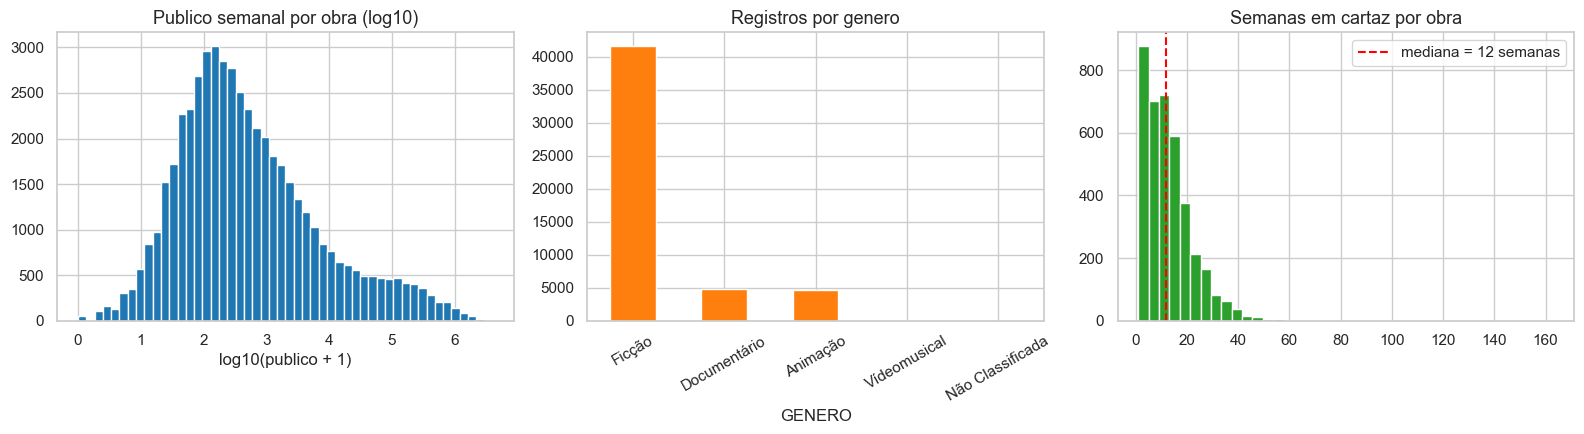

Publico semanal: mediana 323 | media 26,986 | max 4,074,628 (ratio max/mediana = 12,615x)


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Publico semanal por obra (escala log pela assimetria extrema)
axes[0].hist(np.log10(df["PUBLICO"] + 1), bins=50, color="#1f77b4")
axes[0].set_title("Publico semanal por obra (log10)")
axes[0].set_xlabel("log10(publico + 1)")

# Genero (registros semanais)
df["GENERO"].value_counts().plot.bar(ax=axes[1], color="#ff7f0e")
axes[1].set_title("Registros por genero")
axes[1].tick_params(axis="x", rotation=30)

# Semanas em cartaz por obra
axes[2].hist(df_obras["SEMANAS_CARTAZ"], bins=40, color="#2ca02c")
axes[2].axvline(df_obras["SEMANAS_CARTAZ"].median(), color="red", ls="--",
                label=f"mediana = {df_obras['SEMANAS_CARTAZ'].median():.0f} semanas")
axes[2].set_title("Semanas em cartaz por obra")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"Publico semanal: mediana {df['PUBLICO'].median():,.0f} | media {df['PUBLICO'].mean():,.0f} | "
      f"max {df['PUBLICO'].max():,.0f} (ratio max/mediana = {df['PUBLICO'].max()/df['PUBLICO'].median():,.0f}x)")

As distribuições são **extremamente assimétricas**: a mediana de público semanal é de apenas ~300 ingressos, enquanto o topo chega a 4 milhões em uma única semana. Metade das obras some de cartaz em até 3 meses; a exceção chega a 163 semanas (*Relatos Selvagens*). Isso já sinaliza um mercado de **blockbusters** — que a P3 vai quantificar.

### P1 — Como evoluiu o mercado exibidor entre 2009 e 2017?

**Hipótese:** o mercado cresceu em público e, ainda mais, em renda (reajustes de ingresso acima do crescimento de público).

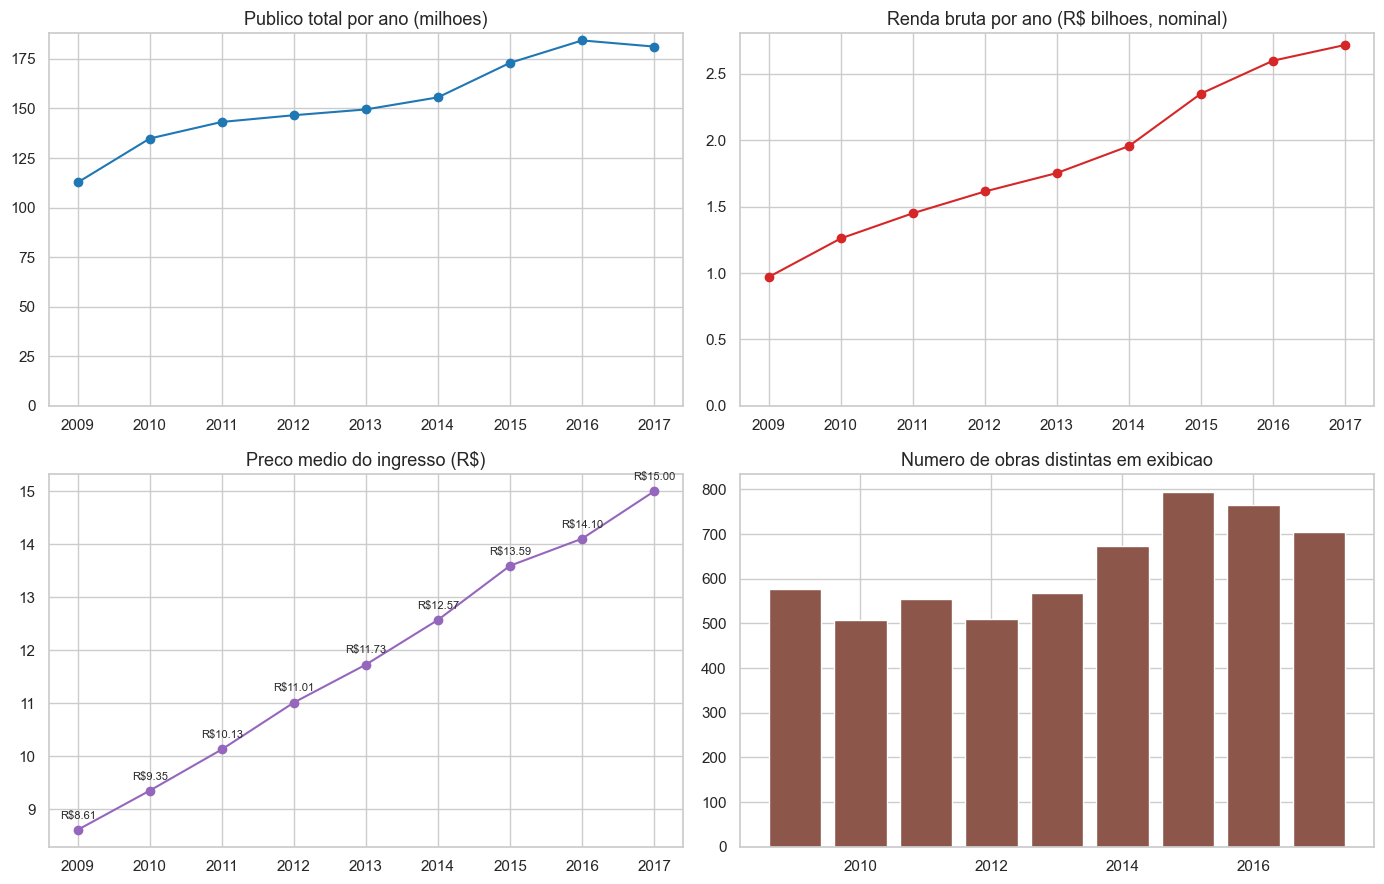

2009 -> 2017:  publico +61% | renda nominal +180% | ticket medio +74%


In [13]:
anual = (
    df.groupby("ANO")
      .agg(PUBLICO=("PUBLICO", "sum"), RENDA=("RENDA", "sum"), OBRAS=("CPB_ROE", "nunique"))
)
anual["TICKET_MEDIO"] = anual["RENDA"] / anual["PUBLICO"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(anual.index, anual["PUBLICO"] / 1e6, marker="o", color="#1f77b4")
axes[0, 0].set_title("Publico total por ano (milhoes)")
axes[0, 0].set_ylim(0)

axes[0, 1].plot(anual.index, anual["RENDA"] / 1e9, marker="o", color="#d62728")
axes[0, 1].set_title("Renda bruta por ano (R$ bilhoes, nominal)")
axes[0, 1].set_ylim(0)

axes[1, 0].plot(anual.index, anual["TICKET_MEDIO"], marker="o", color="#9467bd")
axes[1, 0].set_title("Preco medio do ingresso (R$)")
for x, y in zip(anual.index, anual["TICKET_MEDIO"]):
    axes[1, 0].annotate(f"R${y:.2f}", (x, y), textcoords="offset points",
                        xytext=(0, 8), ha="center", fontsize=8)

axes[1, 1].bar(anual.index, anual["OBRAS"], color="#8c564b")
axes[1, 1].set_title("Numero de obras distintas em exibicao")

plt.tight_layout()
plt.show()

cresc_pub = anual["PUBLICO"].loc[2017] / anual["PUBLICO"].loc[2009] - 1
cresc_ren = anual["RENDA"].loc[2017] / anual["RENDA"].loc[2009] - 1
cresc_tkt = anual["TICKET_MEDIO"].loc[2017] / anual["TICKET_MEDIO"].loc[2009] - 1
print(f"2009 -> 2017:  publico {cresc_pub:+.0%} | renda nominal {cresc_ren:+.0%} | ticket medio {cresc_tkt:+.0%}")

**Leitura:** o público cresceu ~61% no período (112,7M → 181,2M espectadores/ano), mas a renda nominal quase **triplicou** (+180%) — a alavanca principal foi o preço do ingresso, que subiu de R$ 8,61 para R$ 15,00 (+74%, bem acima do IPCA do período). Ao mesmo tempo, o número de obras em cartaz cresceu (576 → 705): mais oferta competindo pelo mesmo espectador, o que aprofunda a lógica de concentração nos lançamentos fortes. 2017 já aponta leve recuo de público — prenúncio do platô que o mercado viveria até a pandemia.

**Hipótese confirmada**, com nuance: a "saúde" do mercado veio muito mais do bolso do espectador do que do crescimento de público.

### P2 — Qual a participação do cinema nacional?

**Hipótese:** obras nacionais são quase um terço do catálogo, mas capturam uma fração muito menor e instável do público — dependente de poucos grandes sucessos por ano.

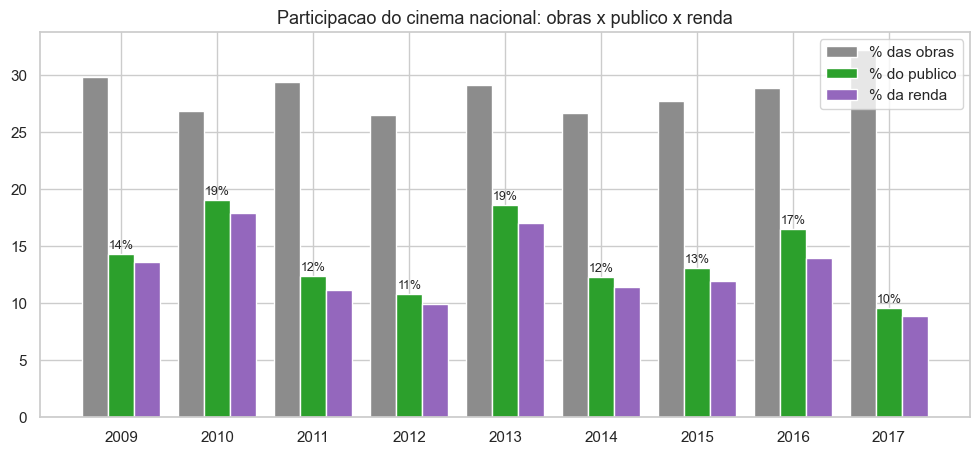

Ticket medio medio por origem/ano (R$):
ORIGEM  Estrangeira  Nacional
ANO                          
2009           7.51      5.82
2010           7.81      6.31
2011           8.19      6.68
2012           9.05      7.79
2013          10.10      8.88
2014          10.55      9.43
2015          11.52     10.10
2016          12.27     10.10
2017          12.63     10.81


In [14]:
nat = df.groupby(["ANO", "ORIGEM"]).agg(PUBLICO=("PUBLICO", "sum"), RENDA=("RENDA", "sum"),
                                        OBRAS=("CPB_ROE", "nunique")).unstack()

share_pub = nat["PUBLICO"]["Nacional"] / nat["PUBLICO"].sum(axis=1) * 100
share_ren = nat["RENDA"]["Nacional"] / nat["RENDA"].sum(axis=1) * 100
share_obr = nat["OBRAS"]["Nacional"] / nat["OBRAS"].sum(axis=1) * 100

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(share_pub.index))
w = 0.27
ax.bar(x - w, share_obr.values, w, label="% das obras", color="#8c8c8c")
ax.bar(x,     share_pub.values, w, label="% do publico", color=COR_NAC)
ax.bar(x + w, share_ren.values, w, label="% da renda", color="#9467bd")
for i, v in enumerate(share_pub.values):
    ax.annotate(f"{v:.0f}%", (i, v), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)
ax.set_xticks(x, share_pub.index)
ax.set_title("Participacao do cinema nacional: obras x publico x renda")
ax.legend()
plt.show()

tkt = df[df["PUBLICO"] > 0].groupby(["ANO", "ORIGEM"])["TICKET_MEDIO"].mean().unstack()
print("Ticket medio medio por origem/ano (R$):")
print(tkt.round(2).to_string())

In [15]:
# Top 10 obras nacionais do periodo
top_nat = df_obras[df_obras["NACIONAL"]].nlargest(10, "PUBLICO")[
    ["TITULO", "ANO", "PUBLICO", "RENDA", "SEMANAS_CARTAZ", "SALAS_MAX"]]
top_nat["RENDA_MI"] = (top_nat["RENDA"] / 1e6).round(1)
top_nat["PUBLICO_MI"] = (top_nat["PUBLICO"] / 1e6).round(2)
top_nat[["TITULO", "ANO", "PUBLICO_MI", "RENDA_MI", "SEMANAS_CARTAZ", "SALAS_MAX"]]

,TITULO,ANO,PUBLICO_MI,RENDA_MI,SEMANAS_CARTAZ,SALAS_MAX
901,OS DEZ MANDAMENTOS,2016,11.31,116.80,37,1127
288,TROPA DE ELITE 2,2010,11.15,103.50,28,763
1018,MINHA MÃE É UMA PEÇA 2,2016,9.23,124.70,18,1125
141,SE EU FOSSE VOCÊ 2,2009,5.79,47.60,44,315
493,DE PERNAS PRO AR 2,2012,4.85,50.30,15,718
546,MINHA MÃE É UMA PEÇA,2013,4.60,49.50,19,407
273,NOSSO LAR,2010,4.06,36.10,15,444
625,ATÉ QUE A SORTE NOS SEPARE 2,2013,3.98,45.30,17,778
770,LOUCAS PRA CASAR,2015,3.73,45.70,20,604
294,DE PERNAS PRO AR,2010,3.51,31.00,28,346


**Leitura:** o cinema nacional responde por **~29% das obras** em cartaz, mas sua fatia de público oscila entre **9,6% e 19,1%** ao ano — e a de renda acompanha de perto. Os picos (2010 e 2013/2016) coincidem com megassucessos pontuais: *Tropa de Elite 2* (11,1M de espectadores, 2010), *Os Dez Mandamentos* (11,3M, 2016) e *Minha Mãe É uma Peça 2* (9,2M, 2016) — os três estão entre os 10 maiores públicos **gerais** do período, à frente de quase todo blockbuster estrangeiro.

Detalhe fino: o ingresso médio de obra nacional saiu mais barato (média ~R$ 8,50 vs ~R$ 9,90 da estrangeira — provável efeito de menos sessões 3D/salas premium), o que achata um pouco mais a fatia de renda.

**Hipótese confirmada:** o "cinema nacional" na bilheteria é, na prática, meia dúzia de campeões por ano carregando uma safra inteira — fora os picos, o share fica na faixa de ~10–14% ao ano.

### P3 — O mercado é concentrado?

**Hipótese:** poucas obras e poucas distribuidoras respondem pela maior parte do público (lei de Pareto).

Top 10 obras concentram 7.3% de TODO o publico do periodo
Para atingir 80% do publico bastam 405 obras (10% do catalogo)


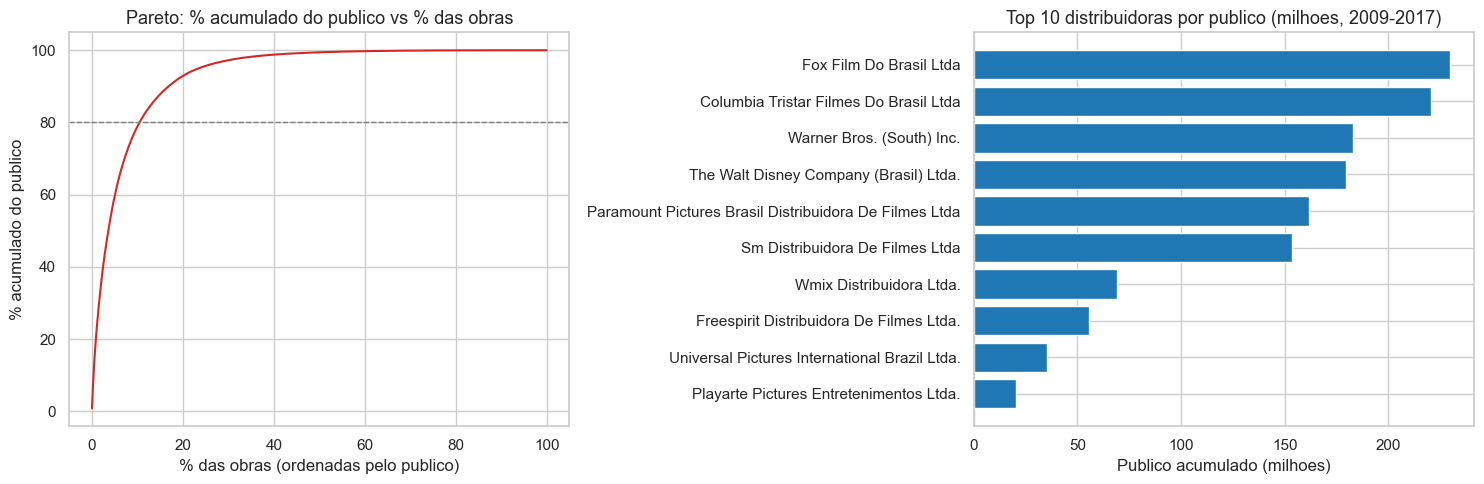

Top 5 distribuidoras: 70.6% do publico | 268 CNPJs no total
Mediana de publico por distribuidora: 2,510


In [16]:
# Curva de Pareto das obras
obras_ord = df_obras.sort_values("PUBLICO", ascending=False).reset_index(drop=True)
cum = obras_ord["PUBLICO"].cumsum() / obras_ord["PUBLICO"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values, color="#d62728")
axes[0].axhline(80, ls="--", color="gray", lw=1)
axes[0].set_title("Pareto: % acumulado do publico vs % das obras")
axes[0].set_xlabel("% das obras (ordenadas pelo publico)")
axes[0].set_ylabel("% acumulado do publico")

top10_share = obras_ord["PUBLICO"].head(10).sum() / obras_ord["PUBLICO"].sum() * 100
n80 = (cum <= 80).sum()
print(f"Top 10 obras concentram {top10_share:.1f}% de TODO o publico do periodo")
print(f"Para atingir 80% do publico bastam {n80} obras ({n80/len(cum):.0%} do catalogo)")

# Distribuidoras (por CNPJ) — top 10 por publico
dist = (df.groupby("CNPJ_DISTRIBUIDORA")
          .agg(DISTRIBUIDORA=("RAZAO_SOCIAL_DISTRIBUIDORA", "first"),
               PUBLICO=("PUBLICO", "sum"), OBRAS=("CPB_ROE", "nunique"))
          .sort_values("PUBLICO", ascending=False))
top_dist = dist.head(10).iloc[::-1]
axes[1].barh(top_dist["DISTRIBUIDORA"].str.title(), top_dist["PUBLICO"] / 1e6, color="#1f77b4")
axes[1].set_title("Top 10 distribuidoras por publico (milhoes, 2009-2017)")
axes[1].set_xlabel("Publico acumulado (milhoes)")

plt.tight_layout()
plt.show()

top5_share = dist["PUBLICO"].head(5).sum() / dist["PUBLICO"].sum() * 100
print(f"Top 5 distribuidoras: {top5_share:.1f}% do publico | {len(dist)} CNPJs no total")
print(f"Mediana de publico por distribuidora: {dist['PUBLICO'].median():,.0f}")

**Leitura:** concentração brutal. Os **10 maiores sucessos de 9 anos** somam 7,3% de todo o público do período — e **apenas ~10% do catálogo (405 obras) responde por 80% de todo o público** (curva de Pareto até mais inclinada que o clássico 80/20). No lado distribuidor, as cinco maiores (Fox, Columbia/Sony, Warner, Disney e Paramount — as majors de Hollywood à época) capturam **70,6%** do público entre 268 CNPJs cadastrados; a mediana de público por distribuidora é irrisória (~2,5 mil espectadores em 9 anos!). O top-10 ainda traz distribuidoras independentes nacionais — SM (grupo Paris/Downtown), WMIX, Freespirit e Playarte —, que entram no pelotão justamente quando carregam os campeões nacionais.

**Hipótese confirmada:** é um mercado de hits. A esmagadora maioria das obras lançadas tem performance marginal — e quem controla os blockbusters controla a bilheteria.

### P4 — Gêneros e países de origem dominantes

**Hipótese:** ficção e animação respondem por quase todo público; EUA domina folgado mesmo contando o Brasil inteiro.

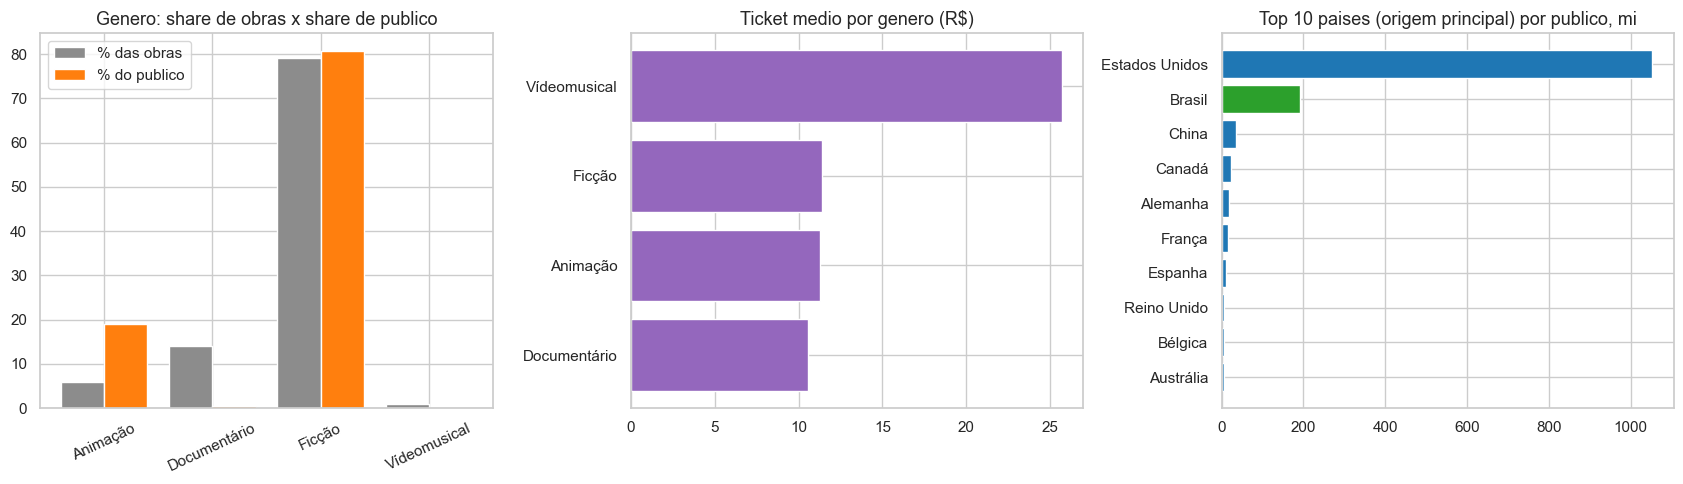

Obras em coproducao internacional: 19% do catalogo
Share de publico do genero Documentario: 0.4% (share de obras: 14%)


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Genero: obras vs publico
g_obras = df_obras.groupby("GENERO")["CPB_ROE"].count()
g_pub = df_obras.groupby("GENERO")["PUBLICO"].sum() / 1e6
x = np.arange(len(g_obras)); w = 0.4
ax0 = axes[0]
ax0.bar(x - w/2, g_obras.values / g_obras.values.sum() * 100, w, label="% das obras", color="#8c8c8c")
ax0.bar(x + w/2, g_pub.values / g_pub.values.sum() * 100, w, label="% do publico", color="#ff7f0e")
ax0.set_xticks(x, g_obras.index, rotation=25)
ax0.set_title("Genero: share de obras x share de publico")
ax0.legend()

# Ticket medio por genero
tkt_g = df_obras.dropna(subset=["TICKET_MEDIO"]).groupby("GENERO")["TICKET_MEDIO"].mean().sort_values()
axes[1].barh(tkt_g.index, tkt_g.values, color="#9467bd")
axes[1].set_title("Ticket medio por genero (R$)")

# Pais principal: top 10 por publico
top_pais = (df_obras.groupby("PAIS_PRINCIPAL")["PUBLICO"].sum()
            .sort_values(ascending=False).head(10).iloc[::-1] / 1e6)
cores = [COR_NAC if p == "Brasil" else COR_ESTR for p in top_pais.index]
axes[2].barh(top_pais.index, top_pais.values, color=cores)
axes[2].set_title("Top 10 paises (origem principal) por publico, mi")

plt.tight_layout()
plt.show()

share_copro = df_obras["CPB_ROE"].isin(df.loc[df["COPRODUCAO"], "CPB_ROE"].unique()).mean()
print(f"Obras em coproducao internacional: {share_copro:.0%} do catalogo")
print(f"Share de publico do genero Documentario: {(g_pub['Documentário']/g_pub.sum()*100):.1f}% "
      f"(share de obras: {g_obras['Documentário']/g_obras.sum()*100:.0f}%)")

**Leitura:** a ficção é ~79% do catálogo e ~81% do público. Os dados mais eloquentes são os extremos: o **documentário** soma 14% das obras exibidas para míseros **0,4% do público** — é o gênero da diversidade cultural, não da bilheteria; já a **animação** faz o caminho inverso, com 6% do catálogo respondendo por ~19% do público (sessões família + ingresso de 3D mais caro).

Nos países, os EUA lideram com folga avassaladora (~1,05 bilhão de espectadores no período); o Brasil aparece em 2º (~192 mi); e logo atrás vêm China e Canadá — não por produção chinesa ou canadense em si, mas porque superproduções de animação dos estúdios americanos são registradas como coproduções com esses países no primeiro lugar da lista. A França, por sua vez, tem volume alto de obras (3º país mais frequente) e público modesto — perfil clássico de circuito de arte. Coproduções internacionais são ~19% do catálogo.

**Hipótese confirmada.**

### P5 — Sazonalidade mensal

**Hipótese:** picos nos meses de férias escolares (janeiro e julho) e vales no "marasmo" de março–maio e outubro–novembro.

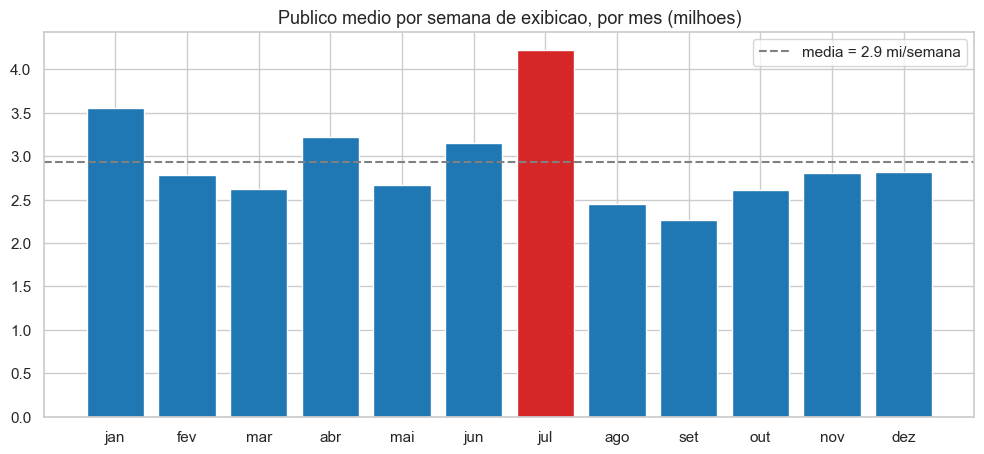

Melhor mes (jul): 4.22 mi/semana | Pior mes (set): 2.27 mi/semana | razao 1.9x


In [18]:
# Publico medio por semana em cada mes (normaliza pelo n. de semanas exibidas no mes)
sem_mes = df.groupby(["MES", "DT_INICIO"]).size().reset_index(name="n")
pub_mes = df.groupby("MES")["PUBLICO"].sum()
sem_uniq = df.groupby("MES")["DT_INICIO"].nunique()
pub_sem = pub_mes / sem_uniq  # publico medio por semana do mes

nomes_mes = ["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"]

fig, ax = plt.subplots(figsize=(12, 5))
cores = ["#d62728" if v == pub_sem.max() else "#1f77b4" for v in pub_sem.values]
ax.bar([nomes_mes[m-1] for m in pub_sem.index], pub_sem.values / 1e6, color=cores)
ax.axhline(pub_sem.mean() / 1e6, ls="--", color="gray", label=f"media = {pub_sem.mean()/1e6:.1f} mi/semana")
ax.set_title("Publico medio por semana de exibicao, por mes (milhoes)")
ax.legend()
plt.show()

razao = pub_sem.max() / pub_sem.min()
print(f"Melhor mes ({nomes_mes[pub_sem.idxmax()-1]}): {pub_sem.max()/1e6:.2f} mi/semana | "
      f"Pior mes ({nomes_mes[pub_sem.idxmin()-1]}): {pub_sem.min()/1e6:.2f} mi/semana | razao {razao:.1f}x")

**Leitura:** a sazonalidade existe e segue o calendário escolar/feriado: **julho** (férias de inverno, mês dos grandes lançamentos família) é disparado o melhor, seguido de **janeiro** (férias de verão + rescaldo do Natal); abril e junho formam um segundo patamar (Páscoa e festas juninas/pré-férias). Os vales aparecem em **setembro, agosto e outubro** — meses sem férias escolares e de janela fraca de lançamentos. A amplitude melhor/pior mês chega a **1,9x** no público semanal — relevante para a janela de lançamento das distribuidoras.

**Hipótese confirmada.**

### P6 — Tempo em cartaz e relação salas × público

**Hipótese:** a vida útil típica é curta, e o público cresce com o número de salas — mas com retorno decrescente (saturação).

Publico semanal mediano POR SALA, por faixa de capilaridade:
faixa
1-10          83.00
11-50        181.00
51-200       305.00
201-500      530.00
501-1000     792.00
1000+      1,229.00


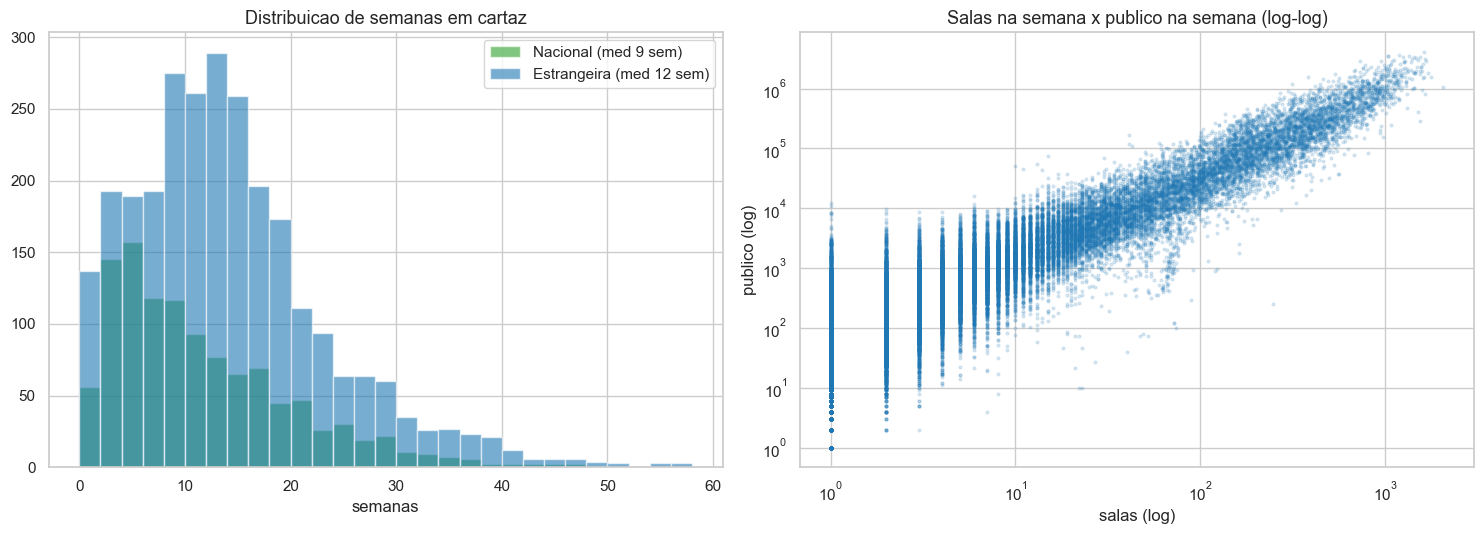


Obras fora de cartaz em ate 4 semanas: 18%
Obras que passam de 26 semanas (6 meses): 9%


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Semanas em cartaz: nacional vs estrangeira
bins = np.arange(0, 60, 2)
for origem, cor in [("Nacional", COR_NAC), ("Estrangeira", COR_ESTR)]:
    s = df_obras.loc[df_obras["ORIGEM"] == origem, "SEMANAS_CARTAZ"]
    axes[0].hist(s, bins=bins, alpha=0.6, label=f"{origem} (med {s.median():.0f} sem)", color=cor)
axes[0].set_title("Distribuicao de semanas em cartaz")
axes[0].set_xlabel("semanas"); axes[0].legend()

# Salas vs publico semanal (log-log)
amostra = df[df["PUBLICO"] > 0]
axes[1].scatter(amostra["SALAS"], amostra["PUBLICO"], s=4, alpha=0.15, color="#1f77b4")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Salas na semana x publico na semana (log-log)")
axes[1].set_xlabel("salas (log)"); axes[1].set_ylabel("publico (log)")

# Publico por sala: faixas de capilaridade
faixas = pd.cut(amostra["SALAS"], [0, 10, 50, 200, 500, 1000, 2100],
                labels=["1-10", "11-50", "51-200", "201-500", "501-1000", "1000+"])
pps = amostra.assign(faixa=faixas).groupby("faixa", observed=True).apply(
    lambda g: (g["PUBLICO"] / g["SALAS"]).median())
print("Publico semanal mediano POR SALA, por faixa de capilaridade:")
print(pps.round(0).to_string())

plt.tight_layout()
plt.show()

sobrev = df_obras["SEMANAS_CARTAZ"]
print(f"\nObras fora de cartaz em ate 4 semanas: {(sobrev <= 4).mean():.0%}")
print(f"Obras que passam de 26 semanas (6 meses): {(sobrev > 26).mean():.0%}")

**Leitura:** a vida útil típica é curta — ~18% das obras saem de cartaz em até 4 semanas e passar de 6 meses é privilégio de ~9% (os "filmões de boca a boca", tipo *Relatos Selvagens* com 163 semanas). A obra nacional tem mediana de 9 semanas em cartaz, contra 12 da estrangeira — janela mais curta, coerente com o share de público menor.

Já o eixo salas × público **refuta** a hipótese de saturação: a correlação no log-log é forte e o rendimento **por sala sobe** com a capilaridade — a obra de circuito de arte (1–10 salas) mediana ~80 espectadores/sala/semana, enquanto o lançamento de 1.000+ salas mediana ~1.230 por sala. Ou seja: blockbuster não é "largamente distribuído apesar do público por sala" — ele tem mais público por sala *e* mais salas. Lançamento amplo é resposta a demanda esperada alta, não diluição.

**Hipótese parcialmente confirmada:** vida útil curta sim, mas sem sinal de retorno decrescente por sala — pelo contrário, o rendimento cresce junto com a capilaridade.

## 5. Síntese: respostas às perguntas

| # | Pergunta | Resposta em uma linha |
|---|----------|------------------------|
| P1 | Evolução do mercado | Público +61%, renda +180% (nominal) — crescimento puxado pelo preço do ingresso (+74%), não por mais frequentadores |
| P2 | Cinema nacional | ~29% das obras → 9,6–19,1% do público, volátil e dependente de 2–3 megassucessos por ano |
| P3 | Concentração | ~10% do catálogo = 80% do público; top-5 distribuidoras (majors) com 70,6% do público |
| P4 | Gêneros/países | Ficção ~80% de tudo; documentário é 14% do catálogo e 0,4% do público; animação fura a cota (6%→19%); EUA 1º, Brasil 2º |
| P5 | Sazonalidade | Picos em jul/jan (férias), vales em set/ago/out — amplitude de 1,9x no público semanal |
| P6 | Janela de exibição | Mediana de 12 semanas em cartaz (nacional: 9); rendimento por sala **sobe** com a capilaridade — blockbuster rende mais por sala, não menos |

**Veredito das hipóteses: 5 confirmadas, 1 parcialmente refutada** (P6 — a saturação por sala não se verifica; lançamentos amplos rendem mais por sala). A exploração ainda trouxe achados não previstos (divergência cadastral CPB vs país de origem, campo `COPIAS` não confiável, ticket nacional mais barato que o estrangeiro).

## 6. Conclusões, Limitações e Trabalhos Futuros

### Conclusões

Entre 2009 e 2017, a bilheteria brasileira cresceu — mas cresceu **pelo preço**, não pelo hábito: o ingresso médio quase dobrou em termos nominais enquanto o público avançou menos. Estruturalmente, é um mercado de **extrema concentração** — nas obras, nas distribuidoras e na origem — em que o cinema nacional existe com volume relevante de produção (1 a cada 3 filmes em cartaz) mas capta uma fatia pequena e instável da arrecadação, sustentada por raros fenômenos de público.

### Limitações

- **Valores nominais:** `RENDA` não é corrigida pela inflação; comparações de renda entre anos distantes devem ser lidas com cautela (o ticket médio calculado é, na verdade, nossa melhor pista de preço).
- **`COPIAS` não confiável** nesta extração — usamos `SALAS` como proxy de capilaridade.
- **Cobertura:** registra-se o que foi reportado à ANCINE; sessões/eventos fora do circuito comercial registrado não entram.
- **Sem variáveis de demanda:** o dataset não traz preço por sessão, tipo de sala (3D/IMAX), horário ou perfil do público — o "ticket médio" é uma razão agregada renda/público.
- **Recorte temporal termina em 2017** — não cobre streaming, pandemia e a recuperação posterior.

### Trabalhos futuros

- Deflacionar a renda pelo IPCA e refazer a série temporal em valores reais;
- Cruzar com `SalasDeExibicaoEComplexos.csv` (parque exibidor por UF) e `ObrasNaoPublicitariasBrasileiras.csv` para análise oferta × demanda por região;
- Segmentar nacionais em "grandes públicos" vs circuito alternativo e testar drivers do sucesso (salas de estreia, gênero, distribuidora);
- Modelo preditivo de público de estreia (regressão/ML) — passo natural num MVP de Machine Learning.

## Referências

- ANCINE — Dados Abertos: *Bilheteria de Obras por Semana* — https://dados.gov.br / https://oca.ancine.gov.br
- ANCINE/OCA — Anuário Estatístico do Cinema Brasileiro
- Documentação pandas, matplotlib e seaborn